## feature A (RFM) + Feature B (loq1n RFM)

## Params

In [1]:
RANDOM_STATE = 42
INIT = "k-means++"
N_INIT = 10
MAX_ITER = 300
TOL = 1e-4

## import thư viện

In [2]:
import json
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

In [3]:
# Chạy từ thư mục notebook, project/ hoặc gốc repository.
relative_dir = Path('notebooks/02_baseline_kmeans/17-11-2026-hieu-kmeans-rfm')
candidates = [Path.cwd(), Path.cwd() / relative_dir, Path.cwd() / 'project' / relative_dir]
BASE_DIR = next((p for p in candidates if (p / 'data/customer_features.csv').is_file()), None)
if BASE_DIR is None:
    raise FileNotFoundError('Không tìm thấy data/customer_features.csv của notebook.')
FIGURES_DIR = BASE_DIR / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)
df = pd.read_csv(BASE_DIR / 'data/customer_features.csv', dtype={'CustomerID': 'string'})
FEATURE_A = ['Recency', 'Frequency', 'Monetary']
X = df[FEATURE_A].copy()
display(X.head())

,Recency,Frequency,Monetary
0,3,7,4310.00
1,76,4,1437.24
2,19,1,1457.55
3,311,1,294.40
4,37,7,1385.74


## Kiểm tra đầu vào (không thay đổi dữ liệu đã tiền xử lý)

In [8]:
display(X.isna().sum().rename('Số giá trị thiếu'))
assert df['CustomerID'].notna().all(), 'CustomerID bị thiếu.'
assert df['CustomerID'].is_unique, 'Cần một dòng cho mỗi CustomerID.'
assert len(X) >= 3, 'Cần ít nhất 3 khách hàng để khảo sát k.'
assert all(pd.api.types.is_numeric_dtype(X[c]) for c in FEATURE_A), 'RFM phải là số.'
assert np.isfinite(X.to_numpy(dtype=float)).all(), 'RFM có missing hoặc giá trị vô hạn.'
assert X['Recency'].ge(0).all(), 'Recency phải không âm.'
assert X['Frequency'].gt(0).all(), 'Frequency phải dương.'
assert X['Monetary'].gt(0).all(), 'Monetary phải dương trong tập mua RFM này.'

Recency      0
Frequency    0
Monetary     0
Name: Số giá trị thiếu, dtype: int64

In [9]:
# Một cấu hình chung cho cả khảo sát k và mô hình cuối.
KMEANS_PARAMS = dict(random_state=RANDOM_STATE, init=INIT, n_init=N_INIT,
                     max_iter=MAX_ITER, tol=TOL)

## Scaling lại dữ liệu

* Do Monetary có giá trị lớn hơn rất nhiều so với Recency và Frequency nên Monetary gần như quyết định toàn bộ khoảng cách giữa các khách hàng.
* Hậu quả là K-Means có thể phân cụm chủ yếu dựa trên số tiền chi tiêu, trong khi Recency và Frequency ít ảnh hưởng đến kết quả.

In [10]:
X = df[FEATURE_A].copy()  
X_t = np.log1p(X)       

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_t)

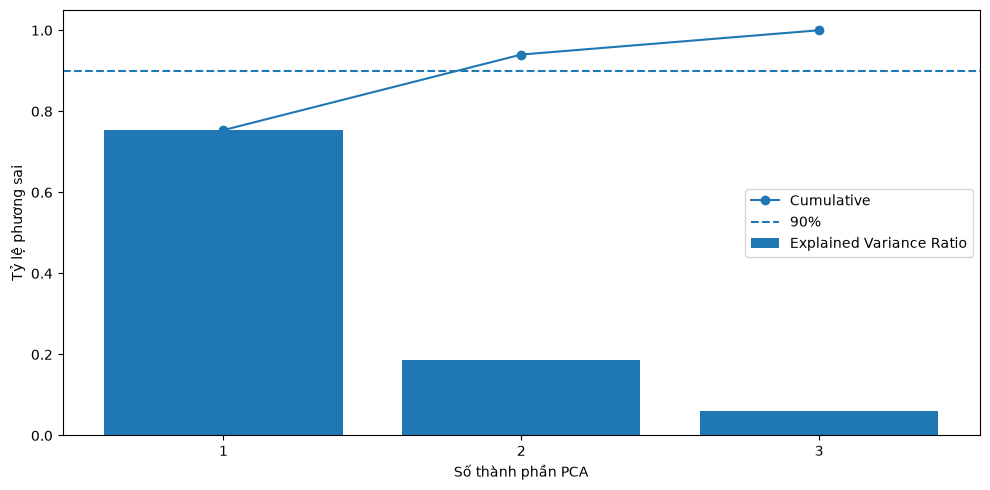

In [11]:
pca_full = PCA(svd_solver="full")
pca_full.fit(X_scaled)
variance = pca_full.explained_variance_ratio_
cumulative = np.cumsum(variance)
components = np.arange(1, len(variance) + 1)
threshold = 0.90

plt.figure(figsize=(10, 5))
plt.plot(components, cumulative, marker="o", label="Cumulative")
plt.axhline(threshold, color="tab:blue", linestyle="--", label=f"{threshold:.0%}")
plt.bar(components, variance, label="Explained Variance Ratio")
plt.xlabel("Số thành phần PCA")
plt.ylabel("Tỷ lệ phương sai")
plt.xticks(components)
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "PCA.png", dpi=300, bbox_inches="tight")
plt.show()

n_components = int(np.searchsorted(cumulative, threshold) + 1)

## PCA giữ tối thiểu 90% phương sai

Nếu phải giữ cả ba thành phần thì PCA chỉ đổi hệ trục, không giảm số chiều. StandardScaler không loại bỏ ảnh hưởng của ngoại lệ; cần xem thêm kích thước và hồ sơ cụm khi diễn giải.

In [12]:
pca_features = PCA(n_components=n_components, svd_solver='full')
X_pca = pca_features.fit_transform(X_scaled)
assert X_pca.shape == (X_scaled.shape[0], n_components)
assert np.isfinite(X_pca).all()
assert pca_features.explained_variance_ratio_.sum() >= threshold - 1e-12
print('Số chiều PCA:', n_components)
print('Phương sai giữ lại:', pca_features.explained_variance_ratio_.sum())
print('Đã giảm chiều.' if n_components < X.shape[1] else 'Giữ đủ các chiều; PCA chỉ đổi hệ trục.')

Số chiều PCA: 2
Phương sai giữ lại: 0.9400607165232948
Đã giảm chiều.


In [13]:
results = []
candidate_models = {}
max_k = min(10, len(X_pca) - 1, len(np.unique(X_pca, axis=0)))
for k in range(2, max_k + 1):
    candidate = KMeans(n_clusters=k, **KMEANS_PARAMS)
    candidate_labels = candidate.fit_predict(X_pca)
    if not 2 <= len(np.unique(candidate_labels)) < len(X_pca):
        continue
    candidate_models[k] = candidate
    results.append({
        'k': k,
        'Silhouette': silhouette_score(X_pca, candidate_labels),
        'DBI': davies_bouldin_score(X_pca, candidate_labels),
        'CHI': calinski_harabasz_score(X_pca, candidate_labels),
        'Inertia': candidate.inertia_,
    })
if not results:
    raise ValueError('Không có phương án k hợp lệ để đánh giá.')
metrics = pd.DataFrame(results)
display(metrics.round(4))

,k,Silhouette,DBI,CHI,Inertia
0,2,0.4639,0.8202,4985.9371,5668.3578
1,3,0.3750,0.9472,4303.4035,4080.6451
2,4,0.3786,0.8984,4135.3729,3153.3842
3,5,0.3655,0.8613,4135.2334,2528.1288
4,6,0.3692,0.8757,4131.0755,2111.1603
5,7,0.3728,0.8285,4149.1052,1804.4720
6,8,0.3691,0.8335,4088.3800,1600.1464
7,9,0.3662,0.8482,4056.5523,1433.0233
8,10,0.3516,0.8323,3976.3344,1313.6646


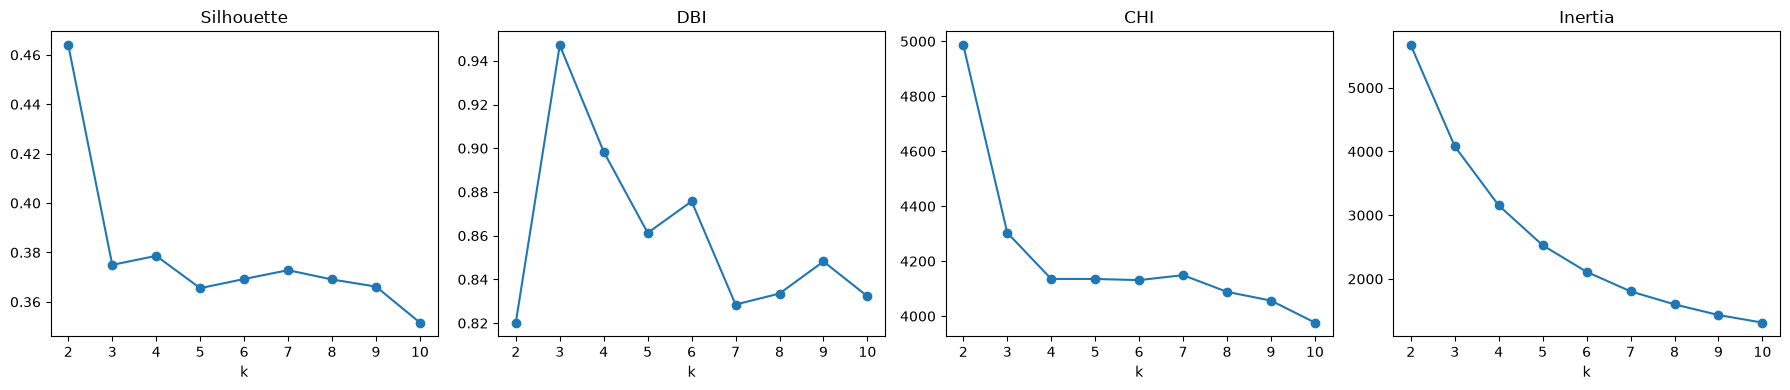

K đề xuất theo Silhouette trong phạm vi khảo sát: 2


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ['Silhouette', 'DBI', 'CHI', 'Inertia']):
    ax.plot(metrics['k'], metrics[col], marker='o')
    ax.set_xlabel('k')
    ax.set_title(col)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'kmeans_metrics.png', dpi=300, bbox_inches='tight')
plt.show()
best_k = int(metrics.loc[metrics['Silhouette'].idxmax(), 'k'])
print('K đề xuất theo Silhouette trong phạm vi khảo sát:', best_k)

In [15]:
best_row = metrics.loc[metrics['k'].eq(best_k)].iloc[0]
dbi_k = int(metrics.loc[metrics['DBI'].idxmin(), 'k'])
chi_k = int(metrics.loc[metrics['CHI'].idxmax(), 'k'])

Sau khi log1p toàn bộ RFM, chọn **k=2** vì Silhouette đạt cao nhất (≈0,464), DBI thấp nhất (≈0,820) và CHI cao nhất (≈4.980) trong phạm vi khảo sát. Inertia giảm dần nhưng chưa có điểm khuỷu rõ ràng. Cần xem thêm quy mô và hồ sơ RFM để đánh giá ý nghĩa của hai cụm.

## Dùng mô hình tốt nhất đã fit trong vòng khảo sát

In [16]:
# Tái sử dụng đúng mô hình được chấm điểm, không fit lại trên RFM gốc.
model = candidate_models[best_k]
labels = model.labels_.copy()
assert np.array_equal(model.predict(X_pca), labels)

In [17]:
result = df[['CustomerID'] + FEATURE_A].copy()
result['cluster'] = labels
print('Số lượng theo cụm:')
display(result['cluster'].value_counts().sort_index())
display(result.head())

Số lượng theo cụm:


cluster
0    1659
1    2668
Name: count, dtype: int64

,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,0
1,12348,76,4,1437.24,0
2,12349,19,1,1457.55,1
3,12350,311,1,294.40,1
4,12352,37,7,1385.74,0


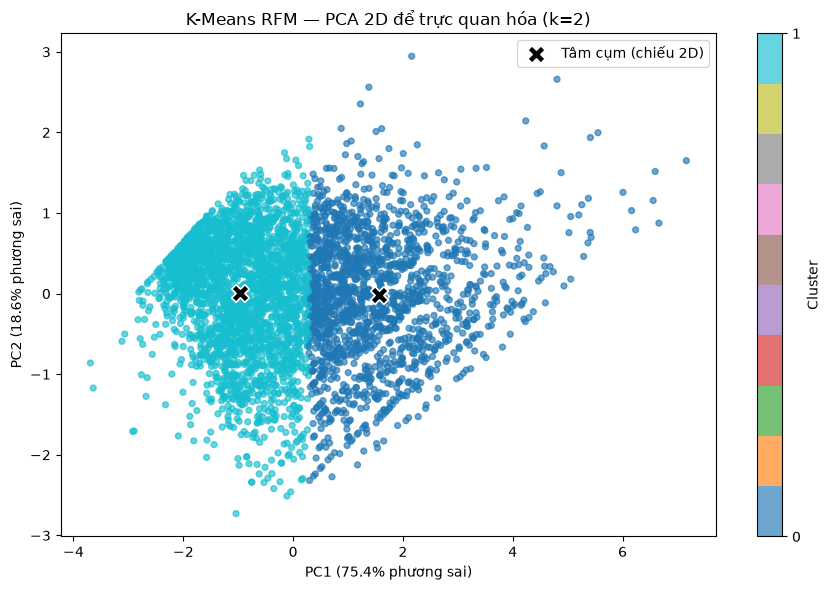

In [18]:
# PCA riêng cho hình vẽ, không thay đổi PCA đầu vào của mô hình.
pca_plot = PCA(n_components=2, svd_solver='full')
coords = pca_plot.fit_transform(X_scaled)
centers_scaled = pca_features.inverse_transform(model.cluster_centers_)
centers_2d = pca_plot.transform(centers_scaled)
fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(coords[:, 0], coords[:, 1], c=labels,
                     cmap='tab10', s=18, alpha=0.65, rasterized=True)
ax.scatter(centers_2d[:, 0], centers_2d[:, 1], c='black', marker='X', s=160,
           edgecolors='white', linewidths=1.2, label='Tâm cụm (chiếu 2D)')
ax.set_title(f'K-Means RFM — PCA 2D để trực quan hóa (k={best_k})')
ax.set_xlabel(f'PC1 ({pca_plot.explained_variance_ratio_[0]:.1%} phương sai)')
ax.set_ylabel(f'PC2 ({pca_plot.explained_variance_ratio_[1]:.1%} phương sai)')
ax.legend(loc='best')
fig.colorbar(scatter, ax=ax, label='Cluster', ticks=sorted(np.unique(labels)))
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'kmeans_clusters_pca.png', dpi=300, bbox_inches='tight')
plt.show()

Biểu đồ cho thấy hai cụm phân tách chủ yếu theo PC1, nhưng vẫn tiếp giáp và chồng lấn ở vùng ranh giới. Hai thành phần PCA thể hiện khoảng 94% tổng phương sai, giúp quan sát phần lớn cấu trúc dữ liệu. Kết quả phù hợp với Silhouette ≈0,464; cần xem thêm hồ sơ RFM để xác định đặc điểm và đặt tên cho từng cụm.

In [19]:
cluster_count = pd.Series(labels).value_counts().sort_index()

cluster_summary = pd.DataFrame({
    "Số khách hàng": cluster_count,
    "Tỷ lệ (%)": (cluster_count / len(labels) * 100).round(2)
})

display(cluster_summary)

,Số khách hàng,Tỷ lệ (%)
0,1659,38.34
1,2668,61.66


In [20]:
cluster_medians = result.groupby('cluster')[FEATURE_A].median()
display(cluster_medians)

,Recency,Frequency,Monetary
cluster,,,
0,17.0,6.0,2020.400
1,97.0,1.0,352.695


* Cụm 0 có trung vị Recency 17 ngày, Frequency 6 hóa đơn và Monetary 2.020,40 GBP, thể hiện nhóm mua gần đây, thường xuyên và chi tiêu cao hơn.
* Cụm 1 có trung vị Recency 97 ngày, Frequency 1 hóa đơn và Monetary 352,70 GBP, thể hiện nhóm đã lâu chưa mua, ít giao dịch và chi tiêu thấp hơn.

## số lượng khách hàng theo từng cụm

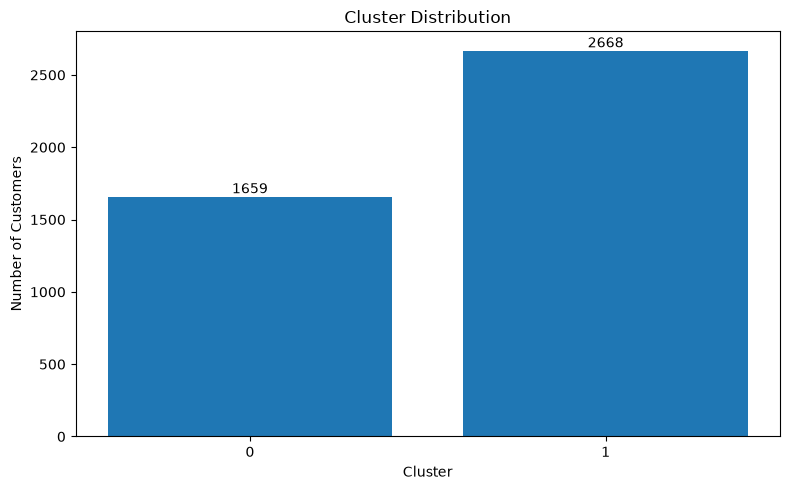

In [21]:
cluster_counts = result["cluster"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(cluster_counts.index, cluster_counts.values)

ax.set_title("Cluster Distribution")
ax.set_xlabel("Cluster")
ax.set_ylabel("Number of Customers")
ax.set_xticks(cluster_counts.index)

for i, count in enumerate(cluster_counts):
    ax.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_cluster_distribution.png", dpi=300)
plt.show()

## RFM theo từng cụm

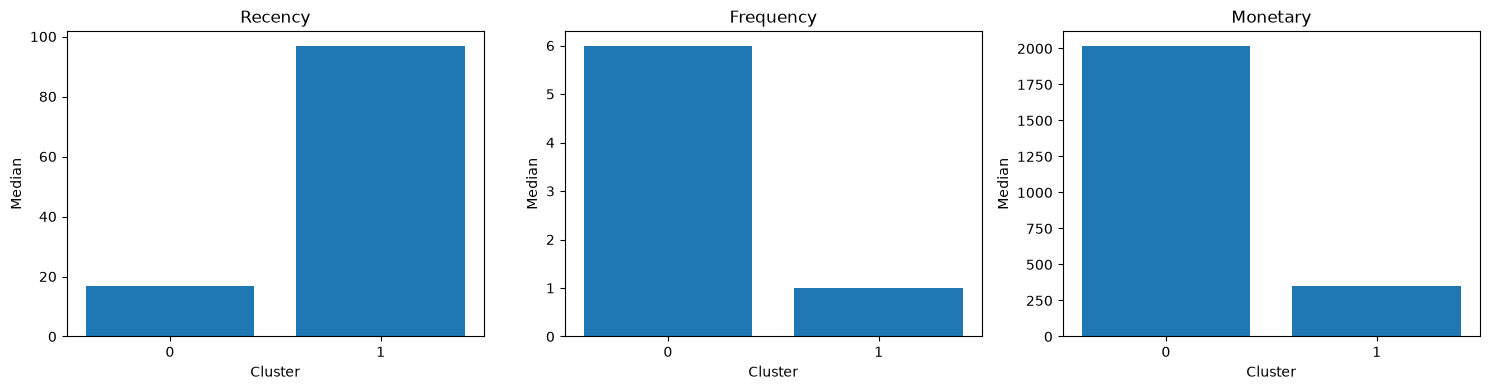

In [22]:
rfm = result.groupby("cluster")[FEATURE_A].median()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, FEATURE_A):
    ax.bar(rfm.index, rfm[feature])
    ax.set_title(feature)
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Median")
    ax.set_xticks(rfm.index)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "kmeans_rfm_comparison.png", dpi=300)
plt.show()

In [23]:
for cluster_id, row in cluster_medians.iterrows():
    count = int(cluster_count.loc[cluster_id])
    display(Markdown(
        f"**Cụm {cluster_id}:** {count:,} khách ({count / len(labels):.2%}); "
        f"trung vị R={row['Recency']:.2f} ngày, F={row['Frequency']:.2f} hóa đơn, "
        f"M={row['Monetary']:.2f} GBP."
    ))

**Cụm 0:** 1,659 khách (38.34%); trung vị R=17.00 ngày, F=6.00 hóa đơn, M=2020.40 GBP.

**Cụm 1:** 2,668 khách (61.66%); trung vị R=97.00 ngày, F=1.00 hóa đơn, M=352.69 GBP.

## Lưu pipeline và kiểm tra nạp lại

`kmeans_model.pkl` chứa Pipeline đã fit (scaler → PCA → K-Means). Đầu vào dự đoán là DataFrame RFM gốc theo FEATURE_A, không chuẩn hóa lần nữa.

In [25]:
from sklearn.preprocessing import FunctionTransformer

pipeline = Pipeline([
    ('log1p', FunctionTransformer(np.log1p, validate=False)),
    ('scaler', scaler),
    ('pca', pca_features),
    ('kmeans', model),
])

model_path = BASE_DIR / 'kmeans_loq_model.pkl'
joblib.dump(pipeline, model_path)

loaded_pipeline = joblib.load(model_path)

# Truyền RFM gốc; pipeline tự log1p rồi chuẩn hóa và PCA.
assert np.array_equal(
    loaded_pipeline.predict(X[FEATURE_A]), labels
), 'Nạp lại không tái lập được nhãn.'